# Expressing the same purpose in Python and Julia


This Julia companion preserves the original source-inspection comparison. Julia 1.0.0 is identified by the public v1.0.0 tag, commit `3a9ff26c7293616a112f0b36eef9beeea892e58c` and registered tree `5498e2c4cd407d421dbb6b193b1f89223af63992`. Every Julia source file used here matches its published Git blob exactly. The release is inspected as text; its package code is not executed or installed. Python 3.2.0 and the original comparison statements are retained. The historical candidate identity and every existing hold remain unchanged.

In [1]:
using CSV,DataFrames,TOML,SHA,Plots
include(joinpath("..","support","BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
configure_plots!()
paths=output_paths("A_risklabai_design")
capsule=normpath(joinpath(@__DIR__,"..","data","appendix03_sources"))
manifest=TOML.parsefile(joinpath(capsule,"sources.toml"))
function captured_source(key)
    record=only(filter(row->row["key"]==key,manifest["sources"]))
    path=joinpath(capsule,record["input"])
    bytes=read(path)
    @assert bytes2hex(sha256(bytes))==record["sha256"]
    if haskey(record,"git_blob_sha1")
        header=Vector{UInt8}(codeunits("blob "*string(length(bytes))*"\0"))
        @assert bytes2hex(sha1(vcat(header,bytes)))==record["git_blob_sha1"]
    end
    return String(bytes)
end
table(frame,name,caption)=save_table(frame,paths,name;caption,label="tab:appendix-"*replace(name,"_"=>"-"))


table (generic function with 1 method)

## Public release boundaries


In [2]:
@assert isdir(capsule)&&isfile(joinpath(capsule,"julia_project.txt"))
julia_project=TOML.parse(captured_source("julia_project"))
python_project=TOML.parse(captured_source("python_project"))
python_version=python_project["project"]["version"]
julia_version=julia_project["version"]
boundaries=DataFrame("Library"=>["RiskLabAI for Python","RiskLabAI for Julia"],"Version used"=>[python_version,julia_version],"Status in this appendix"=>["Released public baseline","Confirmed public baseline"],"Executable here"=>["Yes","No, source inspection only"])
table(boundaries,"python_julia_release_boundaries","Release boundaries used for the software design comparison.")


Row,Library,Version used,Status in this appendix,Executable here
,String,String,String,String
1,RiskLabAI for Python,3.2.0,Released public baseline,Yes
2,RiskLabAI for Julia,1.0.0,Confirmed public baseline,"No, source inspection only"


## Native language choices


In [3]:
python_root=captured_source("python_root")
python_registry=captured_source("python_registry")
python_base=captured_source("python_base")
python_strategy=captured_source("python_strategy")
python_bars=captured_source("python_bars")
python_deprecation=captured_source("python_deprecation")
julia_root=captured_source("julia_root")
julia_validation=captured_source("julia_validation")
julia_cross=captured_source("julia_cross")
julia_types=captured_source("julia_types")
julia_bars=captured_source("julia_bars")
julia_equations=captured_source("julia_equations")
julia_extension=captured_source("julia_extension")
comparison=DataFrame("Purpose"=>["Present a public entry point","Choose behavior","Construct a named component","Vary a bar stopping rule","Load an optional neural solver","Preserve older public use"],"Python design"=>["Module front door with deferred loading","Common interfaces and replaceable strategy objects","Registry maps a name to a constructor","Shared base class with a supplied rule","Deferred import and dependency guard","Deprecation wrappers"],"Julia design"=>["Main module with explicit exports","Types selected through multiple dispatch","Direct construction and dispatched functions","Metric types with dispatched conditions","Weak dependencies and a package extension","Legacy exports retained at the public module"])
table(comparison,"python_julia_design_comparison","How the public Python and Julia libraries express similar software purposes.")


Row,Purpose,Python design,Julia design
,String,String,String
1,Present a public entry point,Module front door with deferred loading,Main module with explicit exports
2,Choose behavior,Common interfaces and replaceable strategy objects,Types selected through multiple dispatch
3,Construct a named component,Registry maps a name to a constructor,Direct construction and dispatched functions
4,Vary a bar stopping rule,Shared base class with a supplied rule,Metric types with dispatched conditions
5,Load an optional neural solver,Deferred import and dependency guard,Weak dependencies and a package extension
6,Preserve older public use,Deprecation wrappers,Legacy exports retained at the public module


## Comparing structure without claiming identical implementations


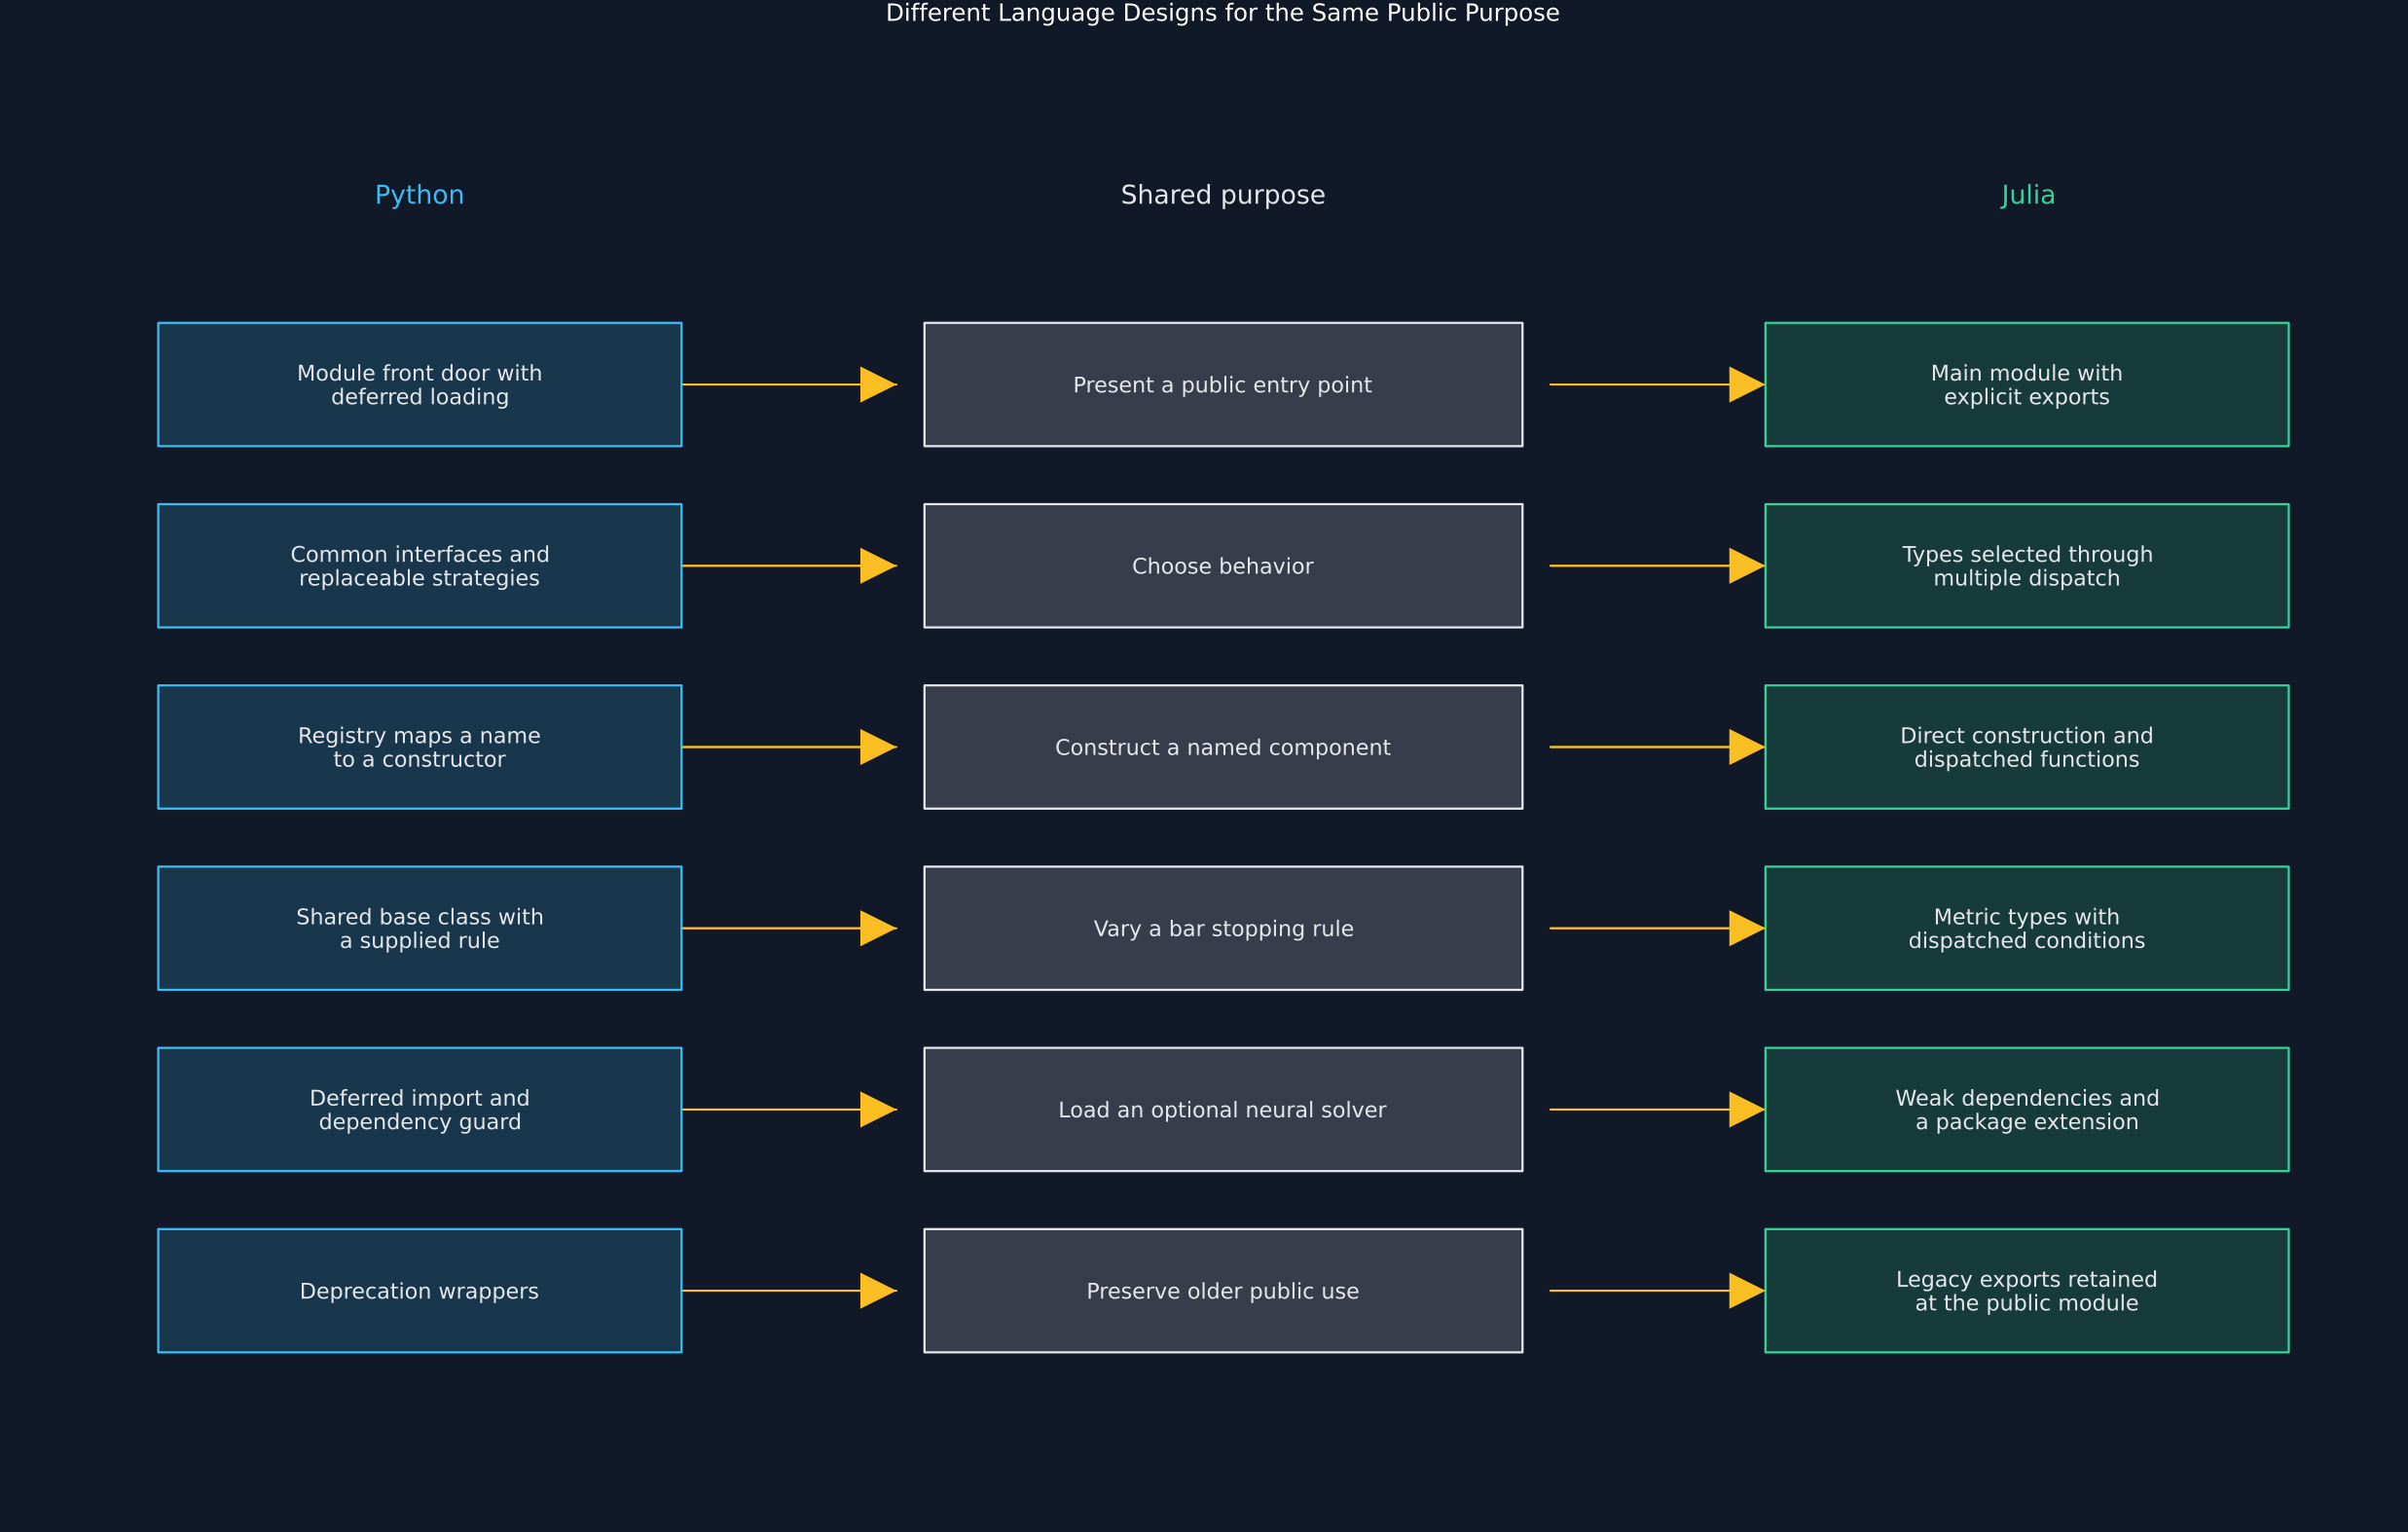

In [4]:
mapping=select(comparison,["Python design","Purpose","Julia design"])
save_data(mapping,paths,"python_julia_design_map")
python_labels=["Module front door with\ndeferred loading","Common interfaces and\nreplaceable strategies","Registry maps a name\nto a constructor","Shared base class with\na supplied rule","Deferred import and\ndependency guard","Deprecation wrappers"]
julia_labels=["Main module with\nexplicit exports","Types selected through\nmultiple dispatch","Direct construction and\ndispatched functions","Metric types with\ndispatched conditions","Weak dependencies and\na package extension","Legacy exports retained\nat the public module"]
figure=plot(;xlim=(-1,11),ylim=(-.8,6.65),axis=false,grid=false,legend=false,title="Different Language Designs for the Same Public Purpose",size=(1650,1050),margin=9Plots.mm)
function design_box!(figure,x,y,width,height,label,color)
    shape=Shape([x-width/2,x+width/2,x+width/2,x-width/2],[y-height/2,y-height/2,y+height/2,y+height/2])
    plot!(figure,shape;color,fillalpha=.18,linecolor=color,linewidth=1.5,label="")
    annotate!(figure,x,y,text(label,10,palette.text,:center))
end
for index in 1:nrow(mapping)
    y=nrow(mapping)-index
    plot!(figure,[2.1,3.25],[y,y];arrow=:closed,color=palette.amber,linewidth=1.3,label="")
    plot!(figure,[6.75,7.9],[y,y];arrow=:closed,color=palette.amber,linewidth=1.3,label="")
    design_box!(figure,.7,y,2.8,.68,python_labels[index],palette.cyan)
    design_box!(figure,5.0,y,3.2,.68,mapping[index,"Purpose"],palette.text)
    design_box!(figure,9.3,y,2.8,.68,julia_labels[index],palette.green)
end
for (x,label,color) in [(.7,"Python",palette.cyan),(5.0,"Shared purpose",palette.text),(9.3,"Julia",palette.green)]
    annotate!(figure,x,6.05,text(label,12,color,:center))
end
save_figure(figure,paths,"python_julia_design_map")


## Tests


In [5]:
@assert python_version=="3.2.0"
@assert julia_version=="1.0.0"
@assert occursin("def __getattr__",python_root)
@assert occursin("class Registry",python_registry)
@assert occursin("class Estimator(Protocol)",python_base)
@assert occursin("class FeatureImportanceStrategy",python_strategy)
@assert occursin("class AbstractBars",python_bars)
@assert occursin("def deprecated",python_deprecation)
@assert occursin("module RiskLabAI",julia_root)
@assert occursin("multiple dispatch",julia_validation)
@assert occursin("struct KFoldCV",julia_cross)
@assert occursin("abstract type Metric",julia_types)
@assert occursin("bar_construction_condition",julia_bars)
@assert occursin("abstract type Equation",julia_equations)
@assert occursin("module RiskLabAIDeepBSDEExt",julia_extension)
@assert julia_project["extensions"]["RiskLabAIDeepBSDEExt"]==["Lux","Optimisers","Zygote"]
display(DataFrame(Test=["Python release","Julia public release","Python deferred front door","Python registry","Python estimator protocol","Python importance strategy","Python bar abstraction","Python deprecation","Julia module","Julia dispatch","Julia cross-validator","Julia metric abstraction","Julia bar condition","Julia equation abstraction","Julia package extension","Julia weak dependencies"],Passed=trues(16)))


Row,Test,Passed
,String,Bool
1,Python release,true
2,Julia public release,true
3,Python deferred front door,true
4,Python registry,true
5,Python estimator protocol,true
6,Python importance strategy,true
7,Python bar abstraction,true
8,Python deprecation,true
9,Julia module,true
